In [ ]:
!pip install kagglehub


In [ ]:
import kagglehub

# Télécharger le dataset (ici l’exemple brain tumor detection)
path = kagglehub.dataset_download("pkdarabi/medical-image-dataset-brain-tumor-detection")
print("Chemin vers les fichiers dataset:", path)


Chemin vers les fichiers dataset: /kaggle/input/medical-image-dataset-brain-tumor-detection


In [ ]:
import os

print("Contenu du dossier dataset:")
print(os.listdir(path))


Contenu du dossier dataset:
['BrainTumor']


In [ ]:
import os

brain_tumor_path = os.path.join(path, "BrainTumor")
print("Contenu BrainTumor:", os.listdir(brain_tumor_path))


Contenu BrainTumor: ['BrainTumorYolov8', 'BrainTumorYolov9', 'BrainTumorYolov11']


In [ ]:
import os

folder_yolo8 = os.path.join(brain_tumor_path, "BrainTumorYolov8")
print("Contenu BrainTumorYolov8 :", os.listdir(folder_yolo8))


Contenu BrainTumorYolov8 : ['data.yaml', 'valid', 'test', 'train']


In [ ]:
train_path = os.path.join(folder_yolo8, "train")
print("Contenu train:", os.listdir(train_path))


Contenu train: ['labels', 'images']


Première image dans train : /kaggle/input/medical-image-dataset-brain-tumor-detection/BrainTumor/BrainTumorYolov8/train/images/493_jpg.rf.c248c2036168a61fefc7e11b421451bb.jpg


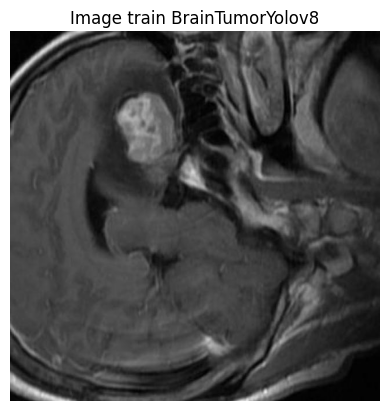

In [ ]:
import os
import cv2
import matplotlib.pyplot as plt

# Fonction pour chercher la première image dans un dossier
def find_first_image(path, extensions=['.jpg', '.jpeg', '.png']):
    for root, dirs, files in os.walk(path):
        for file in files:
            if any(file.lower().endswith(ext) for ext in extensions):
                return os.path.join(root, file)
    return None

# Chemin vers le dossier BrainTumorYolov8/train
folder_yolo8 = os.path.join(brain_tumor_path, "BrainTumorYolov8")
train_path = os.path.join(folder_yolo8, "train")

# Trouver la première image dans train
image_path = find_first_image(train_path)
print("Première image dans train :", image_path)

# Lire et afficher l'image
if image_path:
    image = cv2.imread(image_path)
    if image is None:
        print("Erreur : image non lisible")
    else:
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        plt.imshow(image)
        plt.axis('off')
        plt.title("Image train BrainTumorYolov8")
        plt.show()
else:
    print("Aucune image trouvée dans train.")



In [ ]:
# Installer ultralytics (YOLOv8)
!pip install ultralytics

# Importer les modules nécessaires
from ultralytics import YOLO
import os
import matplotlib.pyplot as plt
import cv2
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay


In [ ]:
import kagglehub

path = kagglehub.dataset_download("pkdarabi/medical-image-dataset-brain-tumor-detection")
brain_tumor_path = os.path.join(path, "BrainTumor", "BrainTumorYolov8")
print("Chemin dataset YOLOv8:", brain_tumor_path)


Chemin dataset YOLOv8: /kaggle/input/medical-image-dataset-brain-tumor-detection/BrainTumor/BrainTumorYolov8


In [ ]:
# Chargement du modèle YOLOv8 pré-entrainé (petit modèle)
model = YOLO("yolov8n.pt")  # 'n' = nano, plus rapide, adapté CPU

# Entraînement (indique chemin vers data.yaml)
model.train(data=os.path.join(brain_tumor_path, "data.yaml"), epochs=2, imgsz=640, device='cpu')


NameError: name 'YOLO' is not defined

In [ ]:
results = model.val()  # évaluation automatique sur val défini dans data.yaml
print(results.box)


Ultralytics 8.3.168 🚀 Python-3.11.13 torch-2.6.0+cu124 CPU (Intel Xeon 2.20GHz)
val: Fast image access ✅ (ping: 0.5±0.4 ms, read: 40.3±7.2 MB/s, size: 34.6 KB)


val: Scanning /kaggle/input/medical-image-dataset-brain-tumor-detection/BrainTumor/BrainTumorYolov8/valid/labels... 612 images, 0 backgrounds, 0 corrupt: 100%|██████████| 612/612 [00:02<00:00, 204.19it/s]

WARNING ⚠️ val: Cache directory /kaggle/input/medical-image-dataset-brain-tumor-detection/BrainTumor/BrainTumorYolov8/valid is not writeable, cache not saved.



                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 39/39 [02:27<00:00,  3.78s/it]


                   all        612        612      0.636      0.612      0.671      0.459
                glioma        285        285      0.435      0.484      0.437      0.242
            meningioma        142        142      0.632      0.817      0.833      0.648
             pituitary        185        185      0.842      0.535      0.742      0.487
Speed: 2.1ms preprocess, 223.1ms inference, 0.0ms loss, 6.7ms postprocess per image
Results saved to runs/detect/train23
ultralytics.utils.metrics.Metric object with attributes:

all_ap: array([[    0.43664,     0.40834,     0.38052,     0.34236,     0.28903,     0.23529,     0.17393,     0.10833,    0.036795,   0.0056646],
       [    0.83276,     0.82685,     0.82685,     0.82012,     0.80806,     0.76962,     0.71369,     0.56549,     0.29567,    0.025326],
       [    0.74243,     0.69193,     0.68488,     0.66013,     0.62217,      0.5557,     0.42559,     0.32203,     0.15123,    0.010383]])
ap: array([    0.24169,     0.64844,   


image 1/1 /kaggle/input/medical-image-dataset-brain-tumor-detection/BrainTumor/BrainTumorYolov8/test/images/2884_jpg.rf.6e1fc048ccc5af32ee622eece72d18b7.jpg: 640x640 1 glioma, 233.4ms
Speed: 4.0ms preprocess, 233.4ms inference, 5.7ms postprocess per image at shape (1, 3, 640, 640)


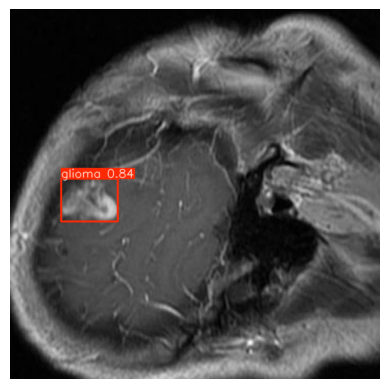

In [ ]:
test_images_path = os.path.join(brain_tumor_path, "test", "images")

# Liste d'images test
test_images = [os.path.join(test_images_path, f) for f in os.listdir(test_images_path) if f.endswith('.jpg')]

# Tester sur la 1ère image
results = model.predict(source=test_images[0], conf=0.25)

# Affichage de l'image avec détection
results[0].plot()
plt.imshow(results[0].plot())
plt.axis('off')
plt.show()


In [ ]:
import os

# Chemin vers le dossier BrainTumorYolov8
base_path = "/kaggle/input/medical-image-dataset-brain-tumor-detection/BrainTumor/BrainTumorYolov8"

# Définir les chemins d'entraînement, validation, test
train_path = os.path.join(base_path, "train")
valid_path = os.path.join(base_path, "valid")
test_path  = os.path.join(base_path, "test")  # <--- Ceci corrige l'erreur

print("Chemin test :", test_path)


results = model.predict(source=test_path, save=True, conf=0.25)


Chemin test : /kaggle/input/medical-image-dataset-brain-tumor-detection/BrainTumor/BrainTumorYolov8/test



FileNotFoundError: No images or videos found in /kaggle/input/medical-image-dataset-brain-tumor-detection/BrainTumor/BrainTumorYolov8/test. Supported formats are:
images: {'jpg', 'tif', 'pfm', 'webp', 'dng', 'png', 'jpeg', 'tiff', 'bmp', 'mpo', 'heic'}
videos: {'mpg', 'webm', 'm4v', 'mov', 'ts', 'avi', 'gif', 'mpeg', 'wmv', 'mp4', 'mkv', 'asf'}

In [ ]:
import os

test_images_dir = os.path.join(test_path, "images")
test_labels_dir = os.path.join(test_path, "labels")

print("Images test :", os.listdir(test_images_dir)[:5])  # Affiche les 5 premières images
print("Labels test :", os.listdir(test_labels_dir)[:5])  # Idem pour les labels



Images test : ['2884_jpg.rf.6e1fc048ccc5af32ee622eece72d18b7.jpg', '571_jpg.rf.ed65129e8c11ba5cc4761d5fbee49eff.jpg', '1650_jpg.rf.f58d91da8f7153f5ec2ba7ecf27a4572.jpg', '2009_jpg.rf.bc09ea2f70c2daed3f2fe5f785bd1a58.jpg', '554_jpg.rf.a4b4fccd77171929d3c2261aceb237b6.jpg']
Labels test : ['445_jpg.rf.9a81d2a3a01aa42d480b9c770cc6ac11.txt', '2959_jpg.rf.b55f5b153b86ea97190b4955ff1568c2.txt', '2242_jpg.rf.2a39144f4a2f0c1e6b3af1631549f60d.txt', '2240_jpg.rf.643b96430344165c1181c859aef3efd5.txt', '234_jpg.rf.19fbc092be70165d474d671de82d77a2.txt']


In [ ]:
results = model.predict(source=test_images_dir, save=True, conf=0.25)



image 1/308 /kaggle/input/medical-image-dataset-brain-tumor-detection/BrainTumor/BrainTumorYolov8/test/images/1003_jpg.rf.028d6d76fba92dd9e5dc59dc9d0f7293.jpg: 640x640 3 gliomas, 2 pituitarys, 338.7ms
image 2/308 /kaggle/input/medical-image-dataset-brain-tumor-detection/BrainTumor/BrainTumorYolov8/test/images/1012_jpg.rf.a9d8d27f5e1d382e0b93ff4a479f4519.jpg: 640x640 1 glioma, 2 pituitarys, 310.4ms
image 3/308 /kaggle/input/medical-image-dataset-brain-tumor-detection/BrainTumor/BrainTumorYolov8/test/images/1018_jpg.rf.29ed2fb6754ca58ae27204ef24344650.jpg: 640x640 1 meningioma, 1 pituitary, 309.6ms
image 4/308 /kaggle/input/medical-image-dataset-brain-tumor-detection/BrainTumor/BrainTumorYolov8/test/images/102_jpg.rf.e58e0fc30dfea3a7a410d7b901223f16.jpg: 640x640 1 meningioma, 333.8ms
image 5/308 /kaggle/input/medical-image-dataset-brain-tumor-detection/BrainTumor/BrainTumorYolov8/test/images/1033_jpg.rf.1b4c0f5bdf30ec0ba218874a3a737720.jpg: 640x640 2 gliomas, 2 pituitarys, 290.2ms
image

In [ ]:
results = model.val()  # utilise les annotations dans valid/


Ultralytics 8.3.168 🚀 Python-3.11.13 torch-2.6.0+cu124 CPU (Intel Xeon 2.20GHz)
val: Fast image access ✅ (ping: 0.8±0.1 ms, read: 38.9±7.8 MB/s, size: 33.3 KB)


val: Scanning /kaggle/input/medical-image-dataset-brain-tumor-detection/BrainTumor/BrainTumorYolov8/valid/labels... 612 images, 0 backgrounds, 0 corrupt: 100%|██████████| 612/612 [00:02<00:00, 226.25it/s]

WARNING ⚠️ val: Cache directory /kaggle/input/medical-image-dataset-brain-tumor-detection/BrainTumor/BrainTumorYolov8/valid is not writeable, cache not saved.



                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 39/39 [02:31<00:00,  3.88s/it]


                   all        612        612      0.636      0.612      0.671      0.459
                glioma        285        285      0.435      0.484      0.437      0.242
            meningioma        142        142      0.632      0.817      0.833      0.648
             pituitary        185        185      0.842      0.535      0.742      0.487
Speed: 1.9ms preprocess, 230.5ms inference, 0.0ms loss, 6.7ms postprocess per image
Results saved to runs/detect/train25


In [ ]:
metrics = results.box

print("Nombre de classes :", metrics.nc)
print("Precision par classe :", metrics.p)
print("Recall par classe :", metrics.r)
print("F1-score par classe :", metrics.f1)
print("AP par classe (mAP@0.5:0.95) :", metrics.all_ap)



Nombre de classes : 3
Precision par classe : [    0.43474     0.63206     0.84192]
Recall par classe : [    0.48421      0.8169     0.53514]
F1-score par classe : [    0.45814     0.71269     0.65435]
AP par classe (mAP@0.5:0.95) : [[    0.43664     0.40834     0.38052     0.34236     0.28903     0.23529     0.17393     0.10833    0.036795   0.0056646]
 [    0.83276     0.82685     0.82685     0.82012     0.80806     0.76962     0.71369     0.56549     0.29567    0.025326]
 [    0.74243     0.69193     0.68488     0.66013     0.62217      0.5557     0.42559     0.32203     0.15123    0.010383]]


In [ ]:
print("mAP@0.5:", sum(metrics.all_ap[:, 0]) / metrics.nc)
print("mAP@0.5:0.95:", sum(metrics.all_ap.mean(axis=1)) / metrics.nc)


mAP@0.5: 0.670608674911021
mAP@0.5:0.95: 0.45892612988889


In [ ]:
import os
import shutil
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt
import cv2
from ultralytics import YOLO
from sklearn.metrics import confusion_matrix, classification_report
import kagglehub

# ===============================
# 1. Charger le modèle YOLO pré-entraîné
# ===============================

# Chemin vers votre modèle dans Google Colab
model_path = "/content/best (3).pt"

# Vérifier si le modèle existe
if not os.path.exists(model_path):
    print(f"❌ Erreur: Le modèle {model_path} n'existe pas!")
    print("Vérifiez le chemin du modèle.")
else:
    print(f"✅ Modèle trouvé: {model_path}")

# Charger le modèle YOLO
try:
    model = YOLO(model_path)
    print("✅ Modèle YOLO chargé avec succès!")
except Exception as e:
    print(f"❌ Erreur lors du chargement du modèle: {e}")

# ===============================
# 2. Préparer le dataset test binaire tumor / no tumor
# ===============================

# Télécharger dataset multi-classes
multi_path = kagglehub.dataset_download("masoudnickparvar/brain-tumor-mri-dataset")
if "brain_tumor_dataset" in os.listdir(multi_path):
    multi_path = os.path.join(multi_path, "brain_tumor_dataset")

multi_test_path = os.path.join(multi_path, "Testing")

# Dossier de test fusionné (binaire)
merged_test_path = "/content/all_data_test"
yes_path = os.path.join(merged_test_path, "yes")
no_path = os.path.join(merged_test_path, "no")

os.makedirs(yes_path, exist_ok=True)
os.makedirs(no_path, exist_ok=True)

tumor_classes = ["glioma", "meningioma", "pituitary"]
notumor_class = "notumor"

def copy_class_with_tracking(src_dir, dst_dir, original_class):
    file_info = []
    if not os.path.exists(src_dir):
        print(f"Warning: {src_dir} does not exist.")
        return file_info

    for fname in os.listdir(src_dir):
        src = os.path.join(src_dir, fname)
        dst = os.path.join(dst_dir, fname)
        if os.path.isfile(src):
            shutil.copy2(src, dst)
            file_info.append({
                'filename': fname,
                'original_class': original_class,
                'binary_class': 'yes' if original_class != 'notumor' else 'no'
            })
    return file_info

file_tracking = []
for cls in tumor_classes:
    file_tracking.extend(copy_class_with_tracking(os.path.join(multi_test_path, cls), yes_path, cls))
file_tracking.extend(copy_class_with_tracking(os.path.join(multi_test_path, notumor_class), no_path, notumor_class))

print(f"✅ Test dataset préparé: {len(file_tracking)} images")

# ===============================
# 3. Collecter toutes les images de test
# ===============================

test_images = []
test_labels = []
test_filenames = []

# Images avec tumeur (yes)
for fname in os.listdir(yes_path):
    if fname.lower().endswith(('.png', '.jpg', '.jpeg')):
        test_images.append(os.path.join(yes_path, fname))
        test_labels.append(1)  # Tumor
        test_filenames.append(fname)

# Images sans tumeur (no)
for fname in os.listdir(no_path):
    if fname.lower().endswith(('.png', '.jpg', '.jpeg')):
        test_images.append(os.path.join(no_path, fname))
        test_labels.append(0)  # No Tumor
        test_filenames.append(fname)

print(f"📊 Total images de test: {len(test_images)}")
print(f"   - Images avec tumeur: {sum(test_labels)}")
print(f"   - Images sans tumeur: {len(test_labels) - sum(test_labels)}")

# ===============================
# 4. Prédictions avec YOLO
# ===============================

print("🚀 Prédictions en cours...")
predictions = []
confidence_threshold = 0.25

try:
    # Faire les prédictions sur toutes les images
    results = model.predict(source=test_images, save=False, conf=confidence_threshold, verbose=False)

    for result in results:
        # Si des détections sont trouvées, considérer comme "tumor"
        if result.boxes and len(result.boxes) > 0:
            predictions.append(1)  # Tumor détecté
        else:
            predictions.append(0)  # Pas de tumor détecté

    print(f"✅ Prédictions terminées: {len(predictions)} résultats")

except Exception as e:
    print(f"❌ Erreur lors des prédictions: {e}")

# ===============================
# 5. Analyse des erreurs par classe d'origine
# ===============================

filename_to_class = {info['filename']: info['original_class'] for info in file_tracking}

fp_classes = []  # Faux positifs
fn_classes = []  # Faux négatifs

for true_label, pred_label, filename in zip(test_labels, predictions, test_filenames):
    original_class = filename_to_class.get(filename, 'unknown')

    # Faux positif: prédit tumor mais c'est no tumor
    if true_label == 0 and pred_label == 1:
        fp_classes.append(original_class)
    # Faux négatif: prédit no tumor mais c'est tumor
    elif true_label == 1 and pred_label == 0:
        fn_classes.append(original_class)

fp_counts = Counter(fp_classes)
fn_counts = Counter(fn_classes)

# ===============================
# 6. Matrice de confusion et métriques
# ===============================

cm = confusion_matrix(test_labels, predictions)
tn, fp_count, fn_count, tp = cm.ravel()

print("\n" + "="*50)
print("📊 RÉSULTATS D'ÉVALUATION")
print("="*50)
print(f"📈 Matrice de Confusion:")
print(f"   TN (Vrai Négatif): {tn}")
print(f"   FP (Faux Positif): {fp_count}")
print(f"   FN (Faux Négatif): {fn_count}")
print(f"   TP (Vrai Positif): {tp}")

# Calcul des métriques
accuracy = (tp + tn) / (tp + tn + fp_count + fn_count) if (tp + tn + fp_count + fn_count) > 0 else 0
precision = tp / (tp + fp_count) if (tp + fp_count) > 0 else 0
recall = tp / (tp + fn_count) if (tp + fn_count) > 0 else 0
f1_score = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0
specificity = tn / (tn + fp_count) if (tn + fp_count) > 0 else 0

print(f"\n📊 Métriques de Performance:")
print(f"   Accuracy (Précision globale): {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"   Precision (Précision positive): {precision:.4f} ({precision*100:.2f}%)")
print(f"   Recall/Sensitivity (Sensibilité): {recall:.4f} ({recall*100:.2f}%)")
print(f"   Specificity (Spécificité): {specificity:.4f} ({specificity*100:.2f}%)")
print(f"   F1-Score: {f1_score:.4f}")

# ===============================
# 7. Analyse détaillée des erreurs
# ===============================

print(f"\n🔍 ANALYSE DES ERREURS")
print("-" * 30)

print(f"🔴 Faux Positifs (prédit TUMOR mais réalité NO TUMOR): {fp_count}")
if fp_counts:
    for cls, count in fp_counts.most_common():
        percentage = (count / fp_count) * 100 if fp_count > 0 else 0
        print(f"   - {cls}: {count} ({percentage:.1f}%)")
else:
    print("   ✅ Aucun faux positif!")

print(f"\n🔴 Faux Négatifs (prédit NO TUMOR mais réalité TUMOR): {fn_count}")
if fn_counts:
    for cls, count in fn_counts.most_common():
        percentage = (count / fn_count) * 100 if fn_count > 0 else 0
        print(f"   - {cls}: {count} ({percentage:.1f}%)")
else:
    print("   ✅ Aucun faux négatif!")

# ===============================
# 8. Visualisation de la matrice de confusion
# ===============================

plt.figure(figsize=(8, 6))
plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
plt.title('Matrice de Confusion - Détection de Tumeurs Cérébrales\n(YOLO Model)', fontsize=14)
plt.colorbar()

tick_marks = np.arange(2)
plt.xticks(tick_marks, ['No Tumor', 'Tumor'], fontsize=12)
plt.yticks(tick_marks, ['No Tumor', 'Tumor'], fontsize=12)

# Ajouter les valeurs dans la matrice
thresh = cm.max() / 2.
for i in range(2):
    for j in range(2):
        plt.text(j, i, f'{cm[i, j]}',
                 horizontalalignment="center",
                 verticalalignment="center",
                 color="white" if cm[i, j] > thresh else "black",
                 fontsize=16, fontweight='bold')

plt.ylabel('Vraie Classe', fontsize=12)
plt.xlabel('Classe Prédite', fontsize=12)
plt.tight_layout()
plt.show()

# ===============================
# 9. Rapport détaillé avec sklearn
# ===============================

print("\n" + "="*50)
print("📋 RAPPORT DE CLASSIFICATION DÉTAILLÉ")
print("="*50)

target_names = ['No Tumor', 'Tumor']
print(classification_report(test_labels, predictions, target_names=target_names))

# ===============================
# 10. Statistiques par classe originale
# ===============================

print(f"\n📊 STATISTIQUES PAR CLASSE ORIGINALE")
print("-" * 40)

# Compter les prédictions par classe originale
class_stats = {}
for true_label, pred_label, filename in zip(test_labels, predictions, test_filenames):
    original_class = filename_to_class.get(filename, 'unknown')

    if original_class not in class_stats:
        class_stats[original_class] = {'correct': 0, 'total': 0, 'tp': 0, 'tn': 0, 'fp': 0, 'fn': 0}

    class_stats[original_class]['total'] += 1

    if true_label == pred_label:
        class_stats[original_class]['correct'] += 1

    # Statistiques détaillées
    if true_label == 1 and pred_label == 1:
        class_stats[original_class]['tp'] += 1
    elif true_label == 0 and pred_label == 0:
        class_stats[original_class]['tn'] += 1
    elif true_label == 0 and pred_label == 1:
        class_stats[original_class]['fp'] += 1
    elif true_label == 1 and pred_label == 0:
        class_stats[original_class]['fn'] += 1

for cls, stats in class_stats.items():
    accuracy_cls = (stats['correct'] / stats['total']) * 100 if stats['total'] > 0 else 0
    print(f"\n{cls.upper()}:")
    print(f"   Total: {stats['total']} images")
    print(f"   Accuracy: {accuracy_cls:.1f}% ({stats['correct']}/{stats['total']})")
    print(f"   TP: {stats['tp']}, TN: {stats['tn']}, FP: {stats['fp']}, FN: {stats['fn']}")

print(f"\n🎯 RÉSUMÉ FINAL")
print(f"   Modèle utilisé: {model_path}")
print(f"   Seuil de confiance: {confidence_threshold}")
print(f"   Performance globale: {accuracy*100:.2f}%")
print(f"   Images testées: {len(test_images)}")

✅ Modèle trouvé: /content/best (3).pt
✅ Modèle YOLO chargé avec succès!
✅ Test dataset préparé: 1311 images
📊 Total images de test: 1311
   - Images avec tumeur: 906
   - Images sans tumeur: 405
🚀 Prédictions en cours...
WARNING ⚠️ 
inference results will accumulate in RAM unless `stream=True` is passed, causing potential out-of-memory
errors for large sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict/ for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

